# Attenomy ML Internship : Week 1 : Task 1.3
## Exploratory Data Analysis & Statistical Hypothesis Testing

**Objective:** Uncover key distributional properties, evaluate statistical hypotheses, and identify collinearity in the benchmark telemetry dataset.

In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(PROJECT_ROOT / "data" / "clean" / "clean.parquet")
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True, errors="coerce")

if df["timestamp"].isna().any():
    raise ValueError("Some timestamps could not be parsed.")

train, temporary = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["is_anomaly"],
)

validation, test = train_test_split(
    temporary,
    test_size=0.50,
    random_state=42,
    stratify=temporary["is_anomaly"],
)

train = train.copy()
validation = validation.copy()
test = test.copy()

train["hour"] = train["timestamp"].dt.hour

sns.set_theme(style="whitegrid")


def save_figure(name):
    plt.tight_layout()
    output_path = FIG_DIR / f"{name}.png"
    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
    print("Saved:", output_path)


print("Dataset:", df.shape)
print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)
print("Training anomaly rate:", round(train["is_anomaly"].mean() * 100, 3), "%")


Dataset: (25000, 13)
Train: (17500, 14)
Validation: (3750, 13)
Test: (3750, 13)
Training anomaly rate: 3.914 %


### 1.Figures 1–4

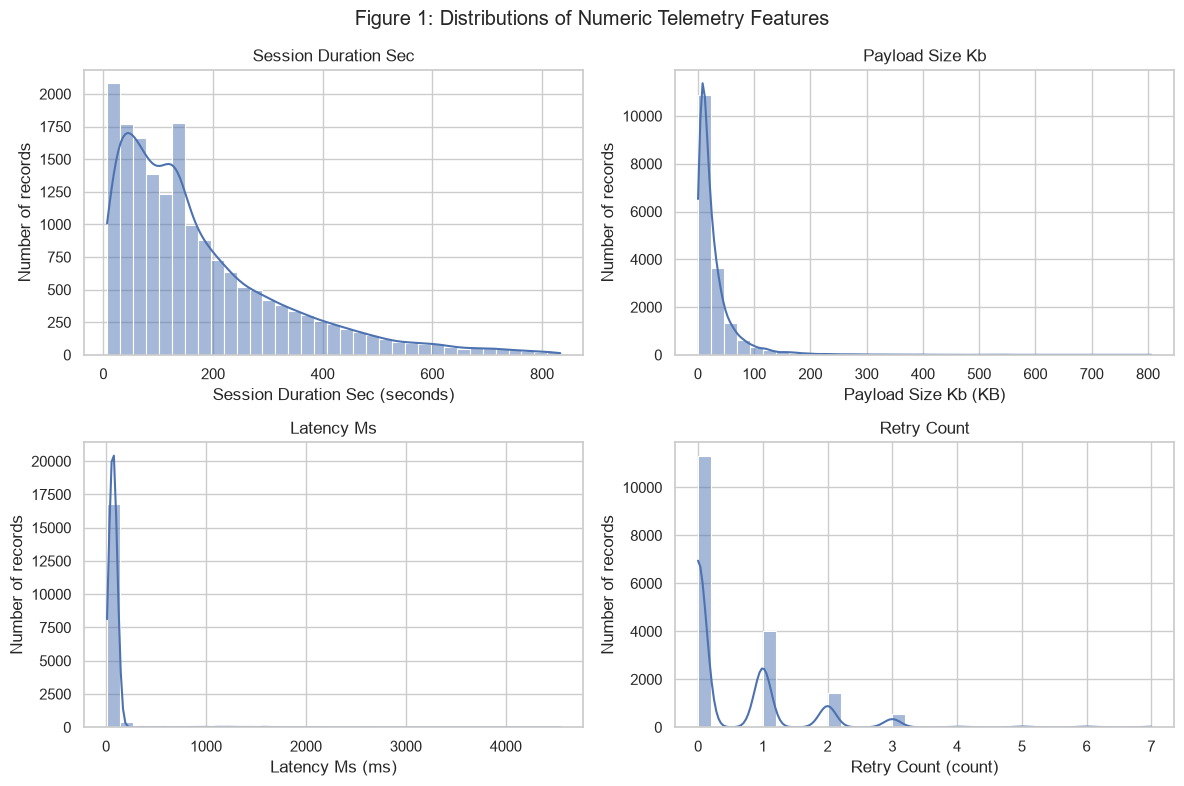

Saved: e:\ml-engineer-internship\reports\figures\fig01_feature_distributions.png
Takeaway: Inspect skew and long tails before selecting transformations or robust models.


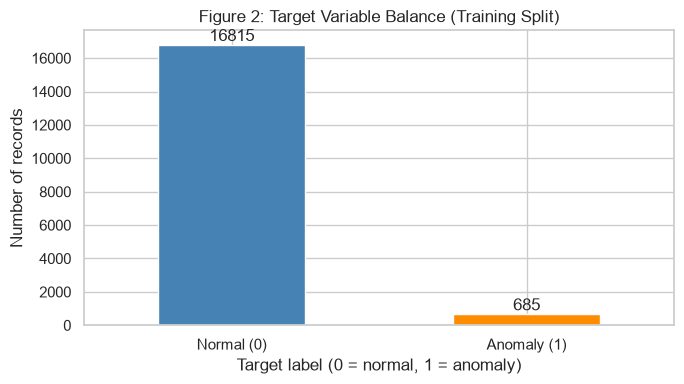

Saved: e:\ml-engineer-internship\reports\figures\fig02_target_balance.png
Takeaway: Anomaly prevalence is 3.91%; evaluate with precision, recall, PR-AUC and a confusion matrix, not accuracy alone.


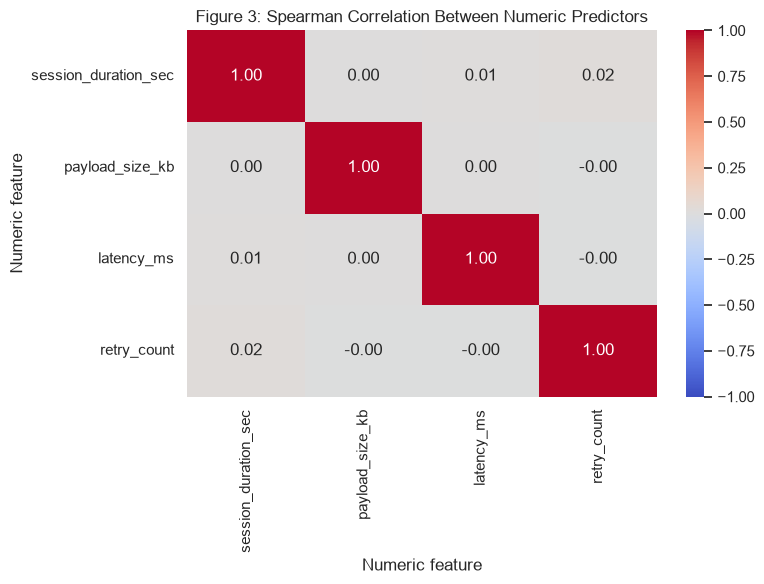

Saved: e:\ml-engineer-internship\reports\figures\fig03_correlation_heatmap.png
Takeaway: Large absolute correlations among predictors may indicate redundancy; verify before dropping features.


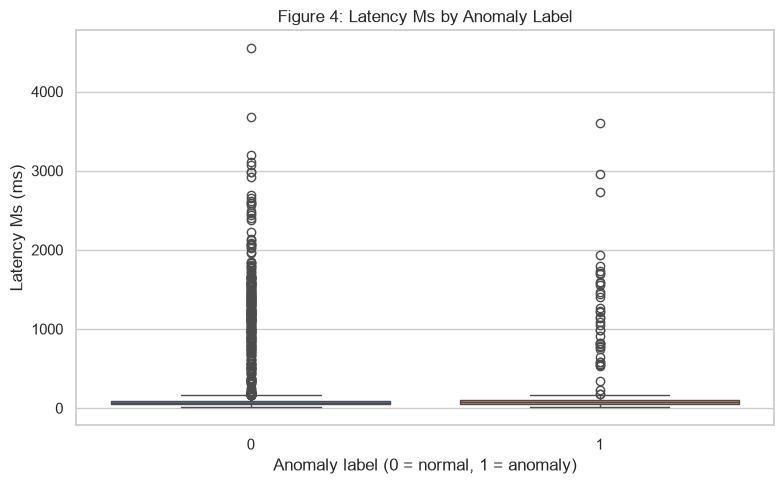

Saved: e:\ml-engineer-internship\reports\figures\fig04_latency_ms_by_target.png
Takeaway: Compare medians and spread between labels for latency_ms; confirm apparent differences with a formal test.


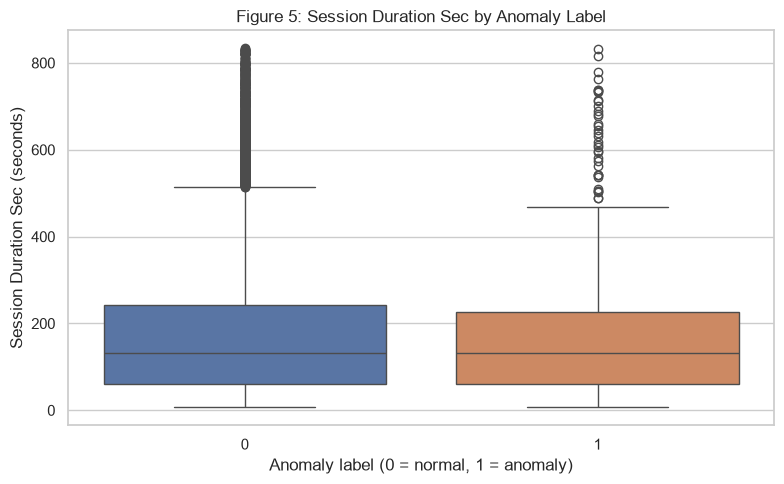

Saved: e:\ml-engineer-internship\reports\figures\fig05_session_duration_sec_by_target.png
Takeaway: Compare medians and spread between labels for session_duration_sec; confirm apparent differences with a formal test.


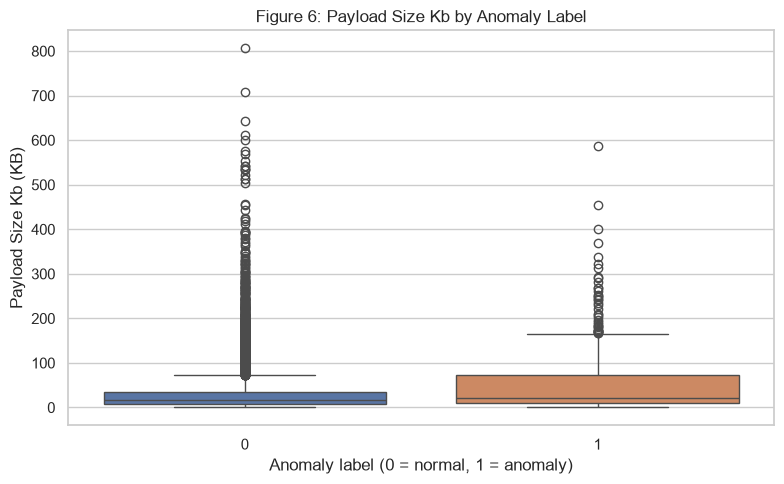

Saved: e:\ml-engineer-internship\reports\figures\fig06_payload_size_kb_by_target.png
Takeaway: Compare medians and spread between labels for payload_size_kb; confirm apparent differences with a formal test.


In [6]:
feature_cols = ["session_duration_sec", "payload_size_kb", "latency_ms", "retry_count"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, feature_cols, strict=True):
    sns.histplot(data=train, x=col, bins=35, kde=True, ax=ax)
    units = {"session_duration_sec": "seconds", "payload_size_kb": "KB", "latency_ms": "ms", "retry_count": "count"}[col]
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel(f"{col.replace('_', ' ').title()} ({units})")
    ax.set_ylabel("Number of records")
fig.suptitle("Figure 1: Distributions of Numeric Telemetry Features")
save_figure("fig01_feature_distributions")
print("Takeaway: Inspect skew and long tails before selecting transformations or robust models.")

counts = train["is_anomaly"].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
counts.plot(kind="bar", ax=ax, color=["steelblue", "darkorange"])
ax.set_title("Figure 2: Target Variable Balance (Training Split)")
ax.set_xlabel("Target label (0 = normal, 1 = anomaly)")
ax.set_ylabel("Number of records")
ax.set_xticks([0, 1], ["Normal (0)", "Anomaly (1)"], rotation=0)
for container in ax.containers: ax.bar_label(container)
save_figure("fig02_target_balance")
print(f"Takeaway: Anomaly prevalence is {train['is_anomaly'].mean():.2%}; evaluate with precision, recall, PR-AUC and a confusion matrix, not accuracy alone.")

corr_cols = ["session_duration_sec", "payload_size_kb", "latency_ms", "retry_count"]
corr = train[corr_cols].corr(method="spearman")
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Figure 3: Spearman Correlation Between Numeric Predictors")
plt.xlabel("Numeric feature")
plt.ylabel("Numeric feature")
save_figure("fig03_correlation_heatmap")
print("Takeaway: Large absolute correlations among predictors may indicate redundancy; verify before dropping features.")

for fig_no, col, units in [
    (4, "latency_ms", "ms"),
    (5, "session_duration_sec", "seconds"),
    (6, "payload_size_kb", "KB"),
]:
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.boxplot(data=train, x="is_anomaly", y=col, hue="is_anomaly", legend=False, ax=ax)
    ax.set_title(f"Figure {fig_no}: {col.replace('_', ' ').title()} by Anomaly Label")
    ax.set_xlabel("Anomaly label (0 = normal, 1 = anomaly)")
    ax.set_ylabel(f"{col.replace('_', ' ').title()} ({units})")
    save_figure(f"fig{fig_no:02d}_{col}_by_target")
    print(f"Takeaway: Compare medians and spread between labels for {col}; confirm apparent differences with a formal test.")


### 2. Figures 5–8

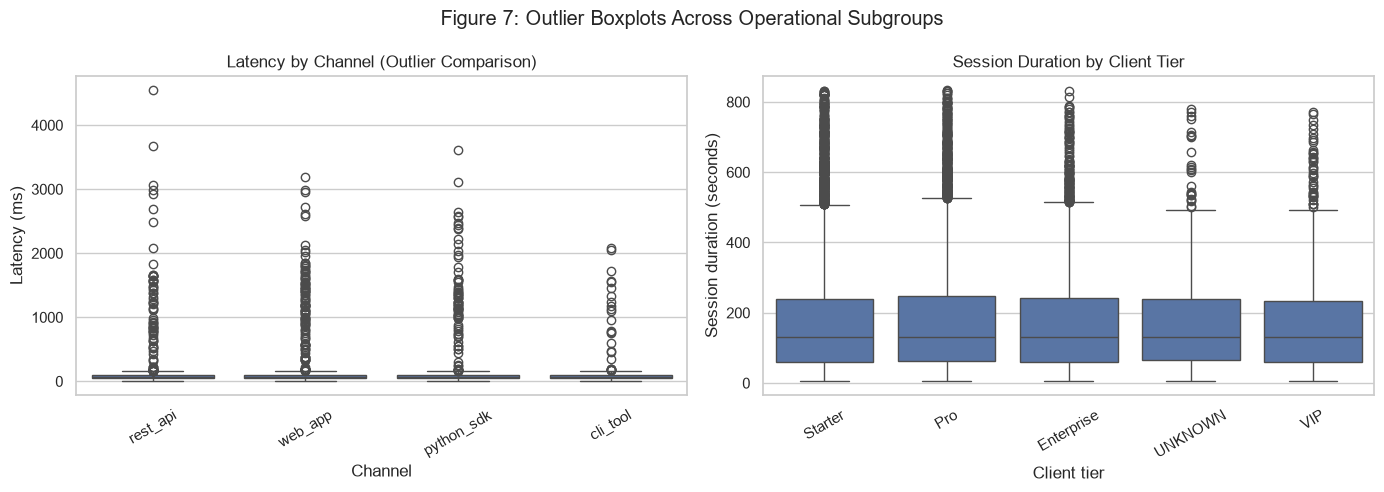

Saved: e:\ml-engineer-internship\reports\figures\fig07_outliers_by_subgroup.png
Takeaway: Points beyond whiskers are potential outliers, not automatic errors; investigate by subgroup and operational context.


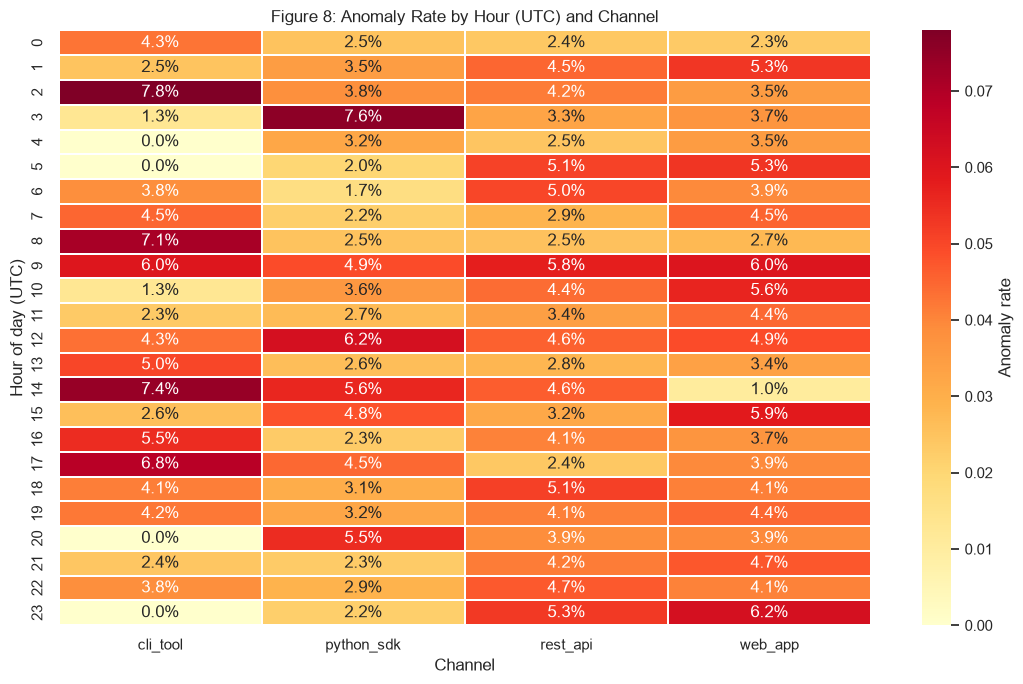

Saved: e:\ml-engineer-internship\reports\figures\fig08_hour_channel_heatmap.png
Takeaway: High-rate cells may identify time/channel combinations for monitoring; interpret cautiously where cell counts are small.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=train, x="channel", y="latency_ms", ax=axes[0])
axes[0].set_title("Latency by Channel (Outlier Comparison)")
axes[0].set_xlabel("Channel")
axes[0].set_ylabel("Latency (ms)")
axes[0].tick_params(axis="x", rotation=30)
sns.boxplot(data=train, x="client_tier", y="session_duration_sec", ax=axes[1])
axes[1].set_title("Session Duration by Client Tier")
axes[1].set_xlabel("Client tier")
axes[1].set_ylabel("Session duration (seconds)")
axes[1].tick_params(axis="x", rotation=30)
fig.suptitle("Figure 7: Outlier Boxplots Across Operational Subgroups")
save_figure("fig07_outliers_by_subgroup")
print("Takeaway: Points beyond whiskers are potential outliers, not automatic errors; investigate by subgroup and operational context.")

# Figure 8 — Temporal/interaction heatmap: anomaly rate by UTC hour and channel
heat = train.pivot_table(index=train["timestamp"].dt.hour, columns="channel", values="is_anomaly", aggfunc="mean", observed=True)
heat = heat.reindex(range(24))
plt.figure(figsize=(11, 7))
sns.heatmap(heat, annot=True, fmt=".1%", cmap="YlOrRd", linewidths=0.3, cbar_kws={"label": "Anomaly rate"})
plt.title("Figure 8: Anomaly Rate by Hour (UTC) and Channel")
plt.xlabel("Channel")
plt.ylabel("Hour of day (UTC)")
save_figure("fig08_hour_channel_heatmap")
print("Takeaway: High-rate cells may identify time/channel combinations for monitoring; interpret cautiously where cell counts are small.")


### 3. Statistical Hypothesis Testing

Perform hypothesis testing to examine the association between selected
telemetry features and `is_anomaly`, the anomaly label.

In [8]:
results = []
alpha = 0.05
categorical_columns = ["interaction_type", "channel", "client_tier", "region", "error_code"]
numeric_columns = ["session_duration_sec", "payload_size_kb", "latency_ms", "retry_count"]

for col in categorical_columns:
    contingency = pd.crosstab(train[col], train["is_anomaly"])
    if contingency.shape[0] < 2 or contingency.shape[1] < 2:
        print(f"Skipping {col}: insufficient categories.")
        continue
    chi2, p_value, dof, expected = stats.chi2_contingency(contingency)
    n = int(contingency.to_numpy().sum())
    v = float(np.sqrt(chi2 / (n * (min(contingency.shape) - 1))))
    results.append({"feature": col, "test": "Chi-square", "null_hypothesis": f"{col} and is_anomaly are independent", "alternative_hypothesis": f"{col} and is_anomaly are associated", "statistic": float(chi2), "degrees_of_freedom": int(dof), "p_value": float(p_value), "effect_size": v, "effect_type": "Cramer's V", "sample_size": n, "min_expected_frequency": float(expected.min())})

for col in numeric_columns:
    a = train.loc[train["is_anomaly"] == 1, col].dropna()
    b = train.loc[train["is_anomaly"] == 0, col].dropna()
    if len(a) == 0 or len(b) == 0:
        print(f"Skipping {col}: insufficient observations.")
        continue
    u, p_value = stats.mannwhitneyu(a, b, alternative="two-sided")
    rb = float((2 * u / (len(a) * len(b))) - 1)
    results.append({"feature": col, "test": "Mann-Whitney U", "null_hypothesis": f"{col} distributions are the same across anomaly labels", "alternative_hypothesis": f"{col} distributions differ across anomaly labels", "statistic": float(u), "degrees_of_freedom": np.nan, "p_value": float(p_value), "effect_size": rb, "effect_type": "Rank-biserial correlation", "sample_size": int(len(a) + len(b)), "min_expected_frequency": np.nan})

results_df = pd.DataFrame(results)
if results_df.empty:
    raise ValueError("No hypothesis tests were completed.")
number_of_tests = len(results_df)
bonferroni_alpha = alpha / number_of_tests
results_df["bonferroni_alpha"] = bonferroni_alpha
results_df["significant_bonferroni"] = results_df["p_value"] < bonferroni_alpha
results_df["business_interpretation"] = results_df.apply(
    lambda r: (f"Evidence of a relationship/difference; assess effect size and operational relevance. {('Warning: minimum expected cell frequency is below 5; Chi-square approximation may be unreliable.' if r['test'] == 'Chi-square' and r['min_expected_frequency'] < 5 else '')}" if r["significant_bonferroni"] else "Insufficient evidence at the Bonferroni-adjusted threshold; this does not prove no relationship."), axis=1)
results_df = results_df.sort_values("p_value").reset_index(drop=True)
display(results_df)

reports_dir = PROJECT_ROOT / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)
results_path = reports_dir / "eda_hypothesis_tests.csv"
summary_path = reports_dir / "eda_summary.csv"
results_df.to_csv(results_path, index=False)
summary = pd.DataFrame({"metric": ["total_rows", "training_rows", "validation_rows", "test_rows", "training_anomaly_count", "training_anomaly_rate", "number_of_hypothesis_tests", "bonferroni_alpha"], "value": [len(df), len(train), len(validation), len(test), int(train["is_anomaly"].sum()), float(train["is_anomaly"].mean()), number_of_tests, bonferroni_alpha]})
summary.to_csv(summary_path, index=False)
print("Hypothesis test results saved to:", results_path)
print("EDA summary saved to:", summary_path)
print("Note: Review Chi-square expected counts and report test statistics, p-values, degrees of freedom where applicable, effect sizes, and business interpretation.")


,feature,test,null_hypothesis,alternative_hypothesis,statistic,degrees_of_freedom,p_value,effect_size,effect_type,sample_size,min_expected_frequency,bonferroni_alpha,significant_bonferroni,business_interpretation
0,error_code,Chi-square,error_code and is_anomaly are independent,error_code and is_anomaly are associated,1.426211e+03,5.0,2.878167e-306,0.285478,Cramer's V,17500,10.764286,0.005556,True,Evidence of a relationship/difference; assess ...
1,retry_count,Mann-Whitney U,retry_count distributions are the same across ...,retry_count distributions differ across anomal...,6.679158e+06,NaN,5.000704e-17,0.159750,Rank-biserial correlation,17500,NaN,0.005556,True,Evidence of a relationship/difference; assess ...
2,payload_size_kb,Mann-Whitney U,payload_size_kb distributions are the same acr...,payload_size_kb distributions differ across an...,6.746490e+06,NaN,2.577577e-14,0.171441,Rank-biserial correlation,17500,NaN,0.005556,True,Evidence of a relationship/difference; assess ...
3,latency_ms,Mann-Whitney U,latency_ms distributions are the same across a...,latency_ms distributions differ across anomaly...,6.146454e+06,NaN,2.803887e-03,0.067252,Rank-biserial correlation,17500,NaN,0.005556,True,Evidence of a relationship/difference; assess ...
4,channel,Chi-square,channel and is_anomaly are independent,channel and is_anomaly are associated,3.869244e+00,3.0,2.759339e-01,0.014869,Cramer's V,17500,69.870000,0.005556,False,Insufficient evidence at the Bonferroni-adjust...
5,interaction_type,Chi-square,interaction_type and is_anomaly are independent,interaction_type and is_anomaly are associated,3.961515e+00,4.0,4.112392e-01,0.015046,Cramer's V,17500,48.184857,0.005556,False,Insufficient evidence at the Bonferroni-adjust...
6,session_duration_sec,Mann-Whitney U,session_duration_sec distributions are the sam...,session_duration_sec distributions differ acro...,5.655144e+06,NaN,4.223261e-01,-0.018057,Rank-biserial correlation,17500,NaN,0.005556,False,Insufficient evidence at the Bonferroni-adjust...
7,region,Chi-square,region and is_anomaly are independent,region and is_anomaly are associated,1.672732e+00,3.0,6.430129e-01,0.009777,Cramer's V,17500,102.202000,0.005556,False,Insufficient evidence at the Bonferroni-adjust...
8,client_tier,Chi-square,client_tier and is_anomaly are independent,client_tier and is_anomaly are associated,1.749957e+00,4.0,7.816242e-01,0.010000,Cramer's V,17500,22.781143,0.005556,False,Insufficient evidence at the Bonferroni-adjust...


Hypothesis test results saved to: e:\ml-engineer-internship\reports\eda_hypothesis_tests.csv
EDA summary saved to: e:\ml-engineer-internship\reports\eda_summary.csv
Note: Review Chi-square expected counts and report test statistics, p-values, degrees of freedom where applicable, effect sizes, and business interpretation.
